# 第三章动态图表 · Python 与 Streamlit
数据来自随附的原始 `第三章 动态图表.xlsm`。依次运行即可显示全部七张图。请将本 Notebook 与 charts.py、data_model.py 和数据文件保存在同一文件夹。

首次使用先在终端运行 `python -m pip install -r requirements.txt`。

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display
from charts import load_data, defaults, draw_chart, NAMES
data = load_data()
state = defaults(data)
print("原工作簿数据读取完成，共 7 类图表。")

原工作簿数据读取完成，共 7 类图表。


## 1. 动态柱形图
修改 state["sales"]（0–5）切换月份。

,类别,数值
0,华北,282
1,华南,323
2,东北,705
3,西北,486
4,西南,405
5,华东,308


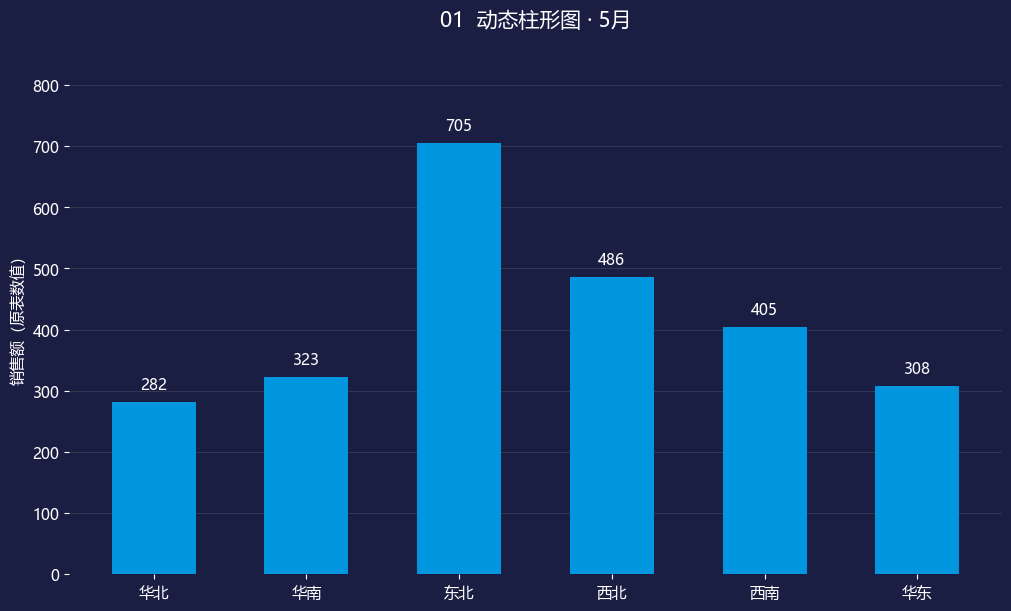

In [2]:
fig, table = draw_chart(data, 0, state)
display(table)
display(fig)
plt.close(fig)

## 2. 动态跑道图
修改 state["people"]（0–3）切换月份；圆弧分母按原图为总人数的一半。

,类别,数值
0,人力部,129
1,行政部,226
2,财务部,226
3,工程部,264
4,采购部,359
5,销售部,433


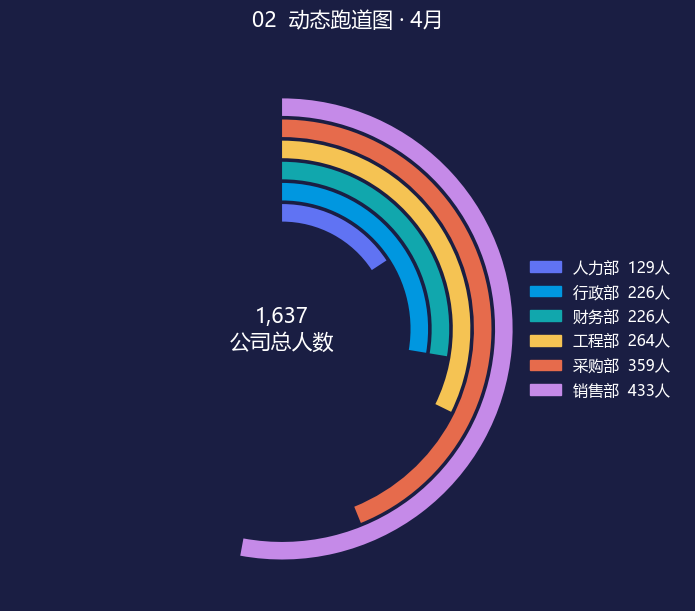

In [3]:
fig, table = draw_chart(data, 1, state)
display(table)
display(fig)
plt.close(fig)

## 3. 动态南丁格尔圆环图
修改 state["rose"]（0–1）切换周期，保留六层嵌套圆环。

,类别,数值
0,首页推荐,0.44
1,关注页面,0.17
2,搜索,0.15
3,个人主页,0.08
4,其他来源,0.16


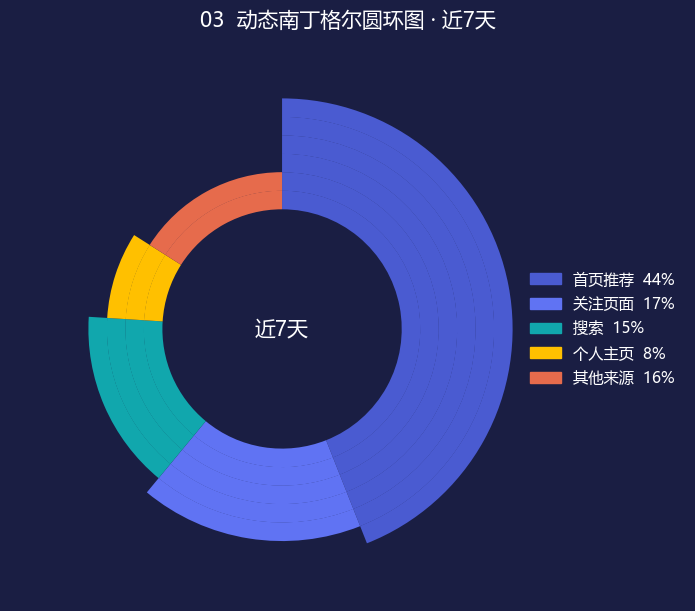

In [4]:
fig, table = draw_chart(data, 2, state)
display(table)
display(fig)
plt.close(fig)

## 4. 动态组合图
修改 state["combo"]，例如 [True, False, True]；双轴对应金额与利润率。

,类别,销售额,利润,利润率
0,口红,2800,1896,0.677143
1,面膜,2564,1563,0.609594
2,隔离,2282,986,0.432077
3,粉底液,2353,1324,0.562686


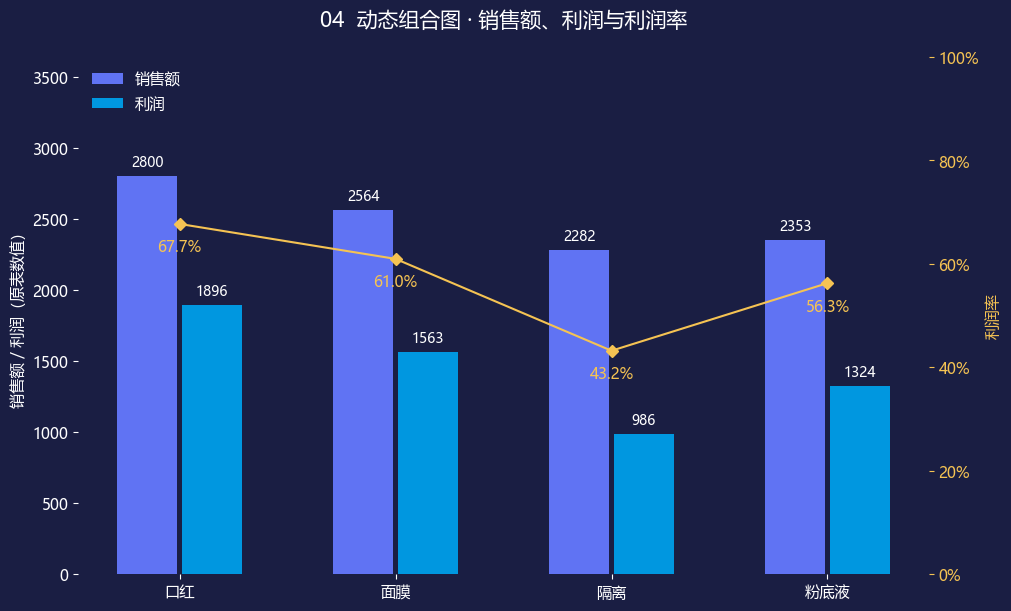

In [5]:
fig, table = draw_chart(data, 3, state)
display(table)
display(fig)
plt.close(fig)

## 5. 透视表切片器
修改 state["departments"] 为部门名列表；多部门按人数加权计算，空选择显示无数据。

,类别,数值,人数
0,本科,6138.317391,230
1,博士,7187.000000,16
2,高中,5853.630137,73
3,硕士,6739.012346,162
4,专科,6908.042017,119


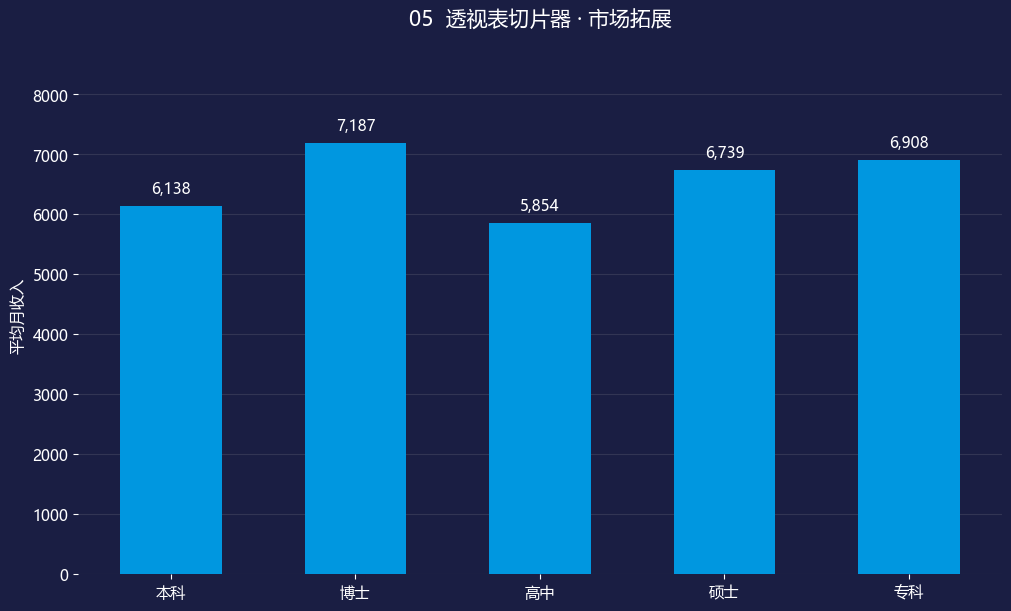

In [6]:
fig, table = draw_chart(data, 4, state)
display(table)
display(fig)
plt.close(fig)

## 6. VBA动态玉玦图
修改 state["jade"]（0–1）切换周期；用 Python 替代 VBA，圆弧分母保留 50%。

,类别,数值
0,个人主页,0.09
1,搜索,0.24
2,关注页面,0.29
3,首页推荐,0.38


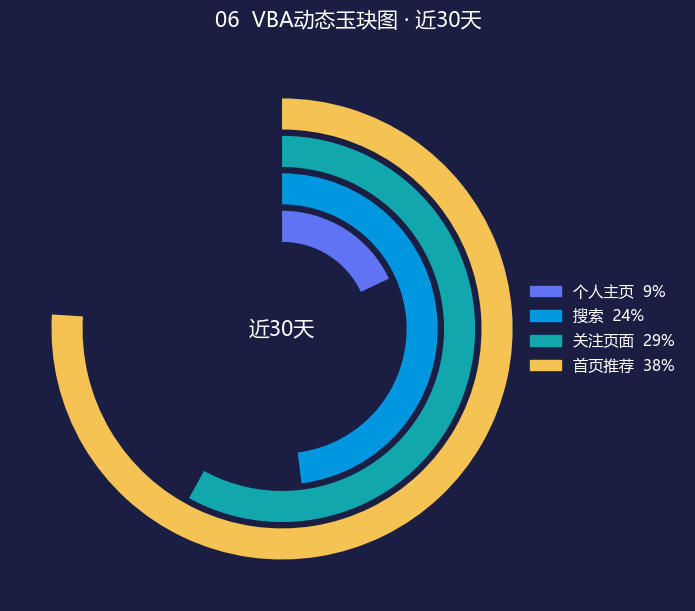

In [7]:
fig, table = draw_chart(data, 5, state)
display(table)
display(fig)
plt.close(fig)

## 7. 动态滑珠图
修改 state["beadMode"]（0=按月份、1=按区域）与 state["beadIndex"]（0–5）。

,类别,数值
0,华北,0.320
1,华南,0.490
2,东北,0.650
3,西北,0.730
4,西南,0.536
5,华东,0.320


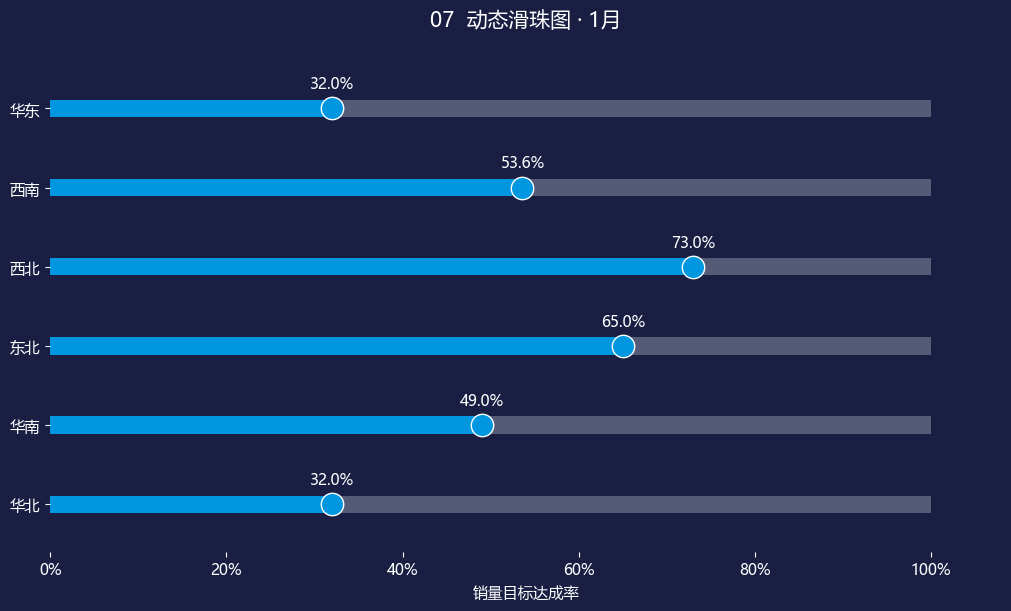

In [8]:
fig, table = draw_chart(data, 6, state)
display(table)
display(fig)
plt.close(fig)

## 启动 Streamlit
把下面的 `START_STREAMLIT` 改成 `True` 再运行。浏览器打开显示的本地地址；默认不启动，以便“运行全部”能直接完成。

In [9]:
START_STREAMLIT = False
if START_STREAMLIT:
    import subprocess, socket, time, urllib.request, webbrowser
    if "streamlit_process" in globals() and streamlit_process.poll() is None:
        print("Streamlit 已在运行：", url)
    else:
        with socket.socket() as sock:
            sock.bind(("127.0.0.1", 0))
            port = sock.getsockname()[1]
        app = Path("app.py").resolve()
        if not app.exists():
            raise FileNotFoundError("请在本 Notebook 所在文件夹启动 Jupyter。")
        log = open(app.with_name("Streamlit启动日志.txt"), "w", encoding="utf-8")
        streamlit_process = subprocess.Popen([sys.executable, "-m", "streamlit", "run", str(app), "--server.address=127.0.0.1", f"--server.port={port}", "--server.headless=true", "--browser.gatherUsageStats=false"], cwd=app.parent, stdout=log, stderr=subprocess.STDOUT)
        log.close()
        url = f"http://127.0.0.1:{port}"
        for attempt in range(60):
            if streamlit_process.poll() is not None:
                raise RuntimeError("启动失败，请查看 Streamlit启动日志.txt")
            try:
                urllib.request.urlopen(url + "/_stcore/health", timeout=1)
                break
            except OSError:
                time.sleep(0.5)
        else:
            raise TimeoutError("启动超时，请查看日志。")
        webbrowser.open(url)
        print("Streamlit 地址：", url)
else:
    print("需要启动网页时，把 START_STREAMLIT 改为 True。")

需要启动网页时，把 START_STREAMLIT 改为 True。


## 停止本 Notebook 启动的服务
需要停止时，把 STOP_STREAMLIT 改为 True。

In [10]:
STOP_STREAMLIT = False
if STOP_STREAMLIT and "streamlit_process" in globals() and streamlit_process.poll() is None:
    streamlit_process.terminate()
    streamlit_process.wait(timeout=10)
    print("已停止。")